In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit
from bisect import bisect_right, bisect_left
import sys
import os
sys.path.append(os.path.abspath(".."))
import Markov_Chains.SingleStrandChain as ssc


# Gillespie algorithm:

In [2]:
@njit(parallel=False)
def run_simulation(runTime: float, Q: np.ndarray):
    times = [0.0]
    states = [0]
    current = 0

    while times[-1] < runTime:
        scale = -1/Q[current, current]
        waitTime = np.random.exponential(scale)
        times.append(times[-1] + waitTime)

        probs = Q[current].copy()
        probs /= -probs[current]
        probs[current] = 0.0

        r = np.random.random()
        cumsum = np.cumsum(probs)
        current = int(np.searchsorted(cumsum, r))
        states.append(current)
    
    states.pop()
    times.pop()

    return states, times

@njit
def set_numba_seed(seed: int):
    """
    Seed the random number generator used inside numba-compiled functions.

    numba keeps its own generator state, separate from NumPy's: calling
    np.random.seed() from ordinary Python code does not affect the random
    numbers drawn inside run_simulation. Seeding must therefore happen from
    within a jitted function, as done here.
    """
    np.random.seed(seed)

# SampleTrajectory:
## Class used to run and visualize trajectories through the CTMC:

In [3]:


class SampleTrajectory:

    def __init__(self, Q, i2s, trunc_dict, run_time=1000):

        """
        Initialize a simulated continuous-time Markov trajectory and its truncated trajectory.

        In intialization, the trajectory is simulated using the Gillespie algorithm. 
        The full trajectory and its truncated version are stored, along with precomputed holding times for each state.

        Args:
            - Q (np.ndarray): Generator (rate) matrix where Q[i, j] is the jump rate i→j and rows sum to 0.
            - i2s (dict[int, str]): Mapping from state index → human-readable state name for full trajectory.
            - trunc_dict (dict[int, str]): Mapping for the truncated (2-state) view, e.g., {0:"Free", 1:"Bound"}.
            - run_time (float): SImulated run time.
        """
        
        self.Q = Q
        self.i2s = i2s
        self.trunc_dict = trunc_dict
        self.run_time = run_time

        self.num_states = len(i2s)

        self.exp_F = -1/Q[0,0]
        self.calc_exp_B()

        self.states = []
        self.times = []
        
        self.truncated_states = []
        self.truncated_times = []

        self.holding_times = {i: [] for i in range(self.num_states)}
        self.holding_times_truncated = {0: [], 1: []}

        self.states, self.times = run_simulation(self.run_time, self.Q)
        self.truncate()

        self.calculate_holding_times()
        self.calculate_holding_times_truncated()



######################## Initialization Methods ##########################


    def truncate(self):
        """
        Build a truncated version of the trajectory, where all states except state 0 are mapped to state 1.
        The truncated trajectory alternates between state 0 ("Free") and state 1 ("Bound").
        0 -> Free
        1 -> Bound (any state other than 0)
        """

        for i in range(len(self.states) - 1):
            if self.states[i] == 0:
                self.truncated_times.append(self.times[i])
                self.truncated_states.append(0)

                self.truncated_times.append(self.times[i+1])
                self.truncated_states.append(1)
        
        if self.states[-1] == 0:
            self.truncated_times.append(self.times[-1])
            self.truncated_states.append(0)

    def calculate_holding_times(self):
        """
        Compute per-state holding times for the full trajectory.

        Fill self.holding_times[s] with durations spent in state `s` between jumps.
        """
        for i in range(len(self.states) - 1):
            holding_time = self.times[i+1] - self.times[i]
            self.holding_times[self.states[i]].append(holding_time)

    def calculate_holding_times_truncated(self):
        """
        Compute holding times for the truncated 2-state trajectory.

        Side Effects:
            Fills`self.holding_times_truncated[] and with segment durations.
        """
        for i in range(len(self.truncated_states) - 1):
            holding_time = self.truncated_times[i+1] - self.truncated_times[i]
            self.holding_times_truncated[self.truncated_states[i]].append(holding_time)

    def calc_exp_B(self):       
        """
        Compute the expected holding time in the bound state for the truncated model.
        """
        sum = 0
        for i in range(1, self.num_states, 2):
            x12 = self.Q[i, i+1]
            x21 = self.Q[i+1, i]
            sum += x12 / x21
            sum += 1
        
        sum *= self.Q[0,1]/self.Q[1,0]
        self.exp_B = sum * self.exp_F

############################# PLOTTING METHODS #############################

    # STEP PLOTS
    def plot_steps(self, palette, title = '', figsize=(10,3), dashed_lines = True, circles = True):
        """
        Plot the full trajectory as a step chart of state vs. time.

        Args:
            palette (dict[int, str]): Color per state index.
            title (str): Figure title.
            figsize (tuple): Matplotlib figure size (w, h).
            dashed_lines (bool): Draw light dashed horizontal guides at each state row.
            circles (bool): Mark segment endpoints with circles.

        Notes:
            Uses self.states and self.times
            extends last segment to self.run_time.
        """
        linewidth = 2
        circle_face_color = 'white'
        circle_size = 7

        plt.figure(figsize = figsize)

        if dashed_lines:
            for i in range(len(self.i2s)):
                plt.axhline(i, color='grey', linestyle=(0, (1, 5)))

        for i in range(len(self.states) - 1):
            s = self.states[i]
            t0, t1 = self.times[i], self.times[i+1]
            color = palette[s]

            plt.hlines(s, t0, t1, color, linewidth=linewidth)
            if(circles):
                plt.plot(t0, s, 'o', color=color, markersize=circle_size)
                plt.plot(t1, s, 'o', markerfacecolor=circle_face_color, markeredgecolor=color, markersize=circle_size, markeredgewidth=linewidth)
        
        s = self.states[-1]
        t0, t1 = self.times[-1], self.run_time
        color = palette[s]

        plt.hlines(s, t0, t1, color, linewidth=linewidth)
        if(circles):
            plt.plot(t0, s, 'o', color=color, markersize=circle_size)
            plt.plot(t1, s, 'o', markerfacecolor=circle_face_color, markeredgecolor=color, markersize=circle_size, markeredgewidth=linewidth)


        plt.yticks([i for i in range(len(self.i2s))], [self.i2s[i] for i in range(len(self.i2s))]) # Set y-ticks to state names

        plt.xlabel("Time")
        plt.ylabel("State")

        plt.title(title)
        ax = plt.gca()
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        
        plt.show()

    def plot_truncated_steps(self, trunc_palette, title = '', figsize=(10,3), dashed_lines = True, circles = True):
        """
        Plot the truncated (2-state) trajectory as a step chart.

        Args:
            trunc_palette (dict[int, str]): Colors for truncated states {0,1}.
            title (str): Figure title.
            figsize (tuple): Matplotlib figure size (w, h).
            dashed_lines (bool): Draw horizontal guides at truncated rows.
            circles (bool): Mark segment endpoints with circles.

        Notes:
            Uses self.states and self.times
            extends last segment to self.run_time.
        """
        
        linewidth = 2
        circle_face_color = 'white'
        circle_size = 7

        plt.figure(figsize = figsize)

        if dashed_lines:
            for i in range(len(self.trunc_dict)):
                plt.axhline(i, color='grey', linestyle=(0, (1, 5)))

        for i in range(len(self.truncated_states) - 1):
            s = self.truncated_states[i]
            t0, t1 = self.truncated_times[i], self.truncated_times[i+1]
            color = trunc_palette[s]

            plt.hlines(s, t0, t1, color, linewidth=linewidth)
            if(circles):
                plt.plot(t0, s, 'o', color=color, markersize=circle_size)
                plt.plot(t1, s, 'o', markerfacecolor=circle_face_color, markeredgecolor=color, markersize=circle_size, markeredgewidth=linewidth)
        
        s = self.truncated_states[-1]
        t0, t1 = self.truncated_times[-1], self.run_time
        color = trunc_palette[s]

        plt.hlines(s, t0, t1, color, linewidth=linewidth)

        if(circles):
            plt.plot(t0, s, 'o', color=color, markersize=circle_size)
            plt.plot(t1, s, 'o', markerfacecolor=circle_face_color, markeredgecolor=color, markersize=circle_size, markeredgewidth=linewidth)


        plt.yticks([i for i in range(len(self.trunc_dict))], [self.trunc_dict[i] for i in range(len(self.trunc_dict))])

        plt.xlabel("Time")
        plt.ylabel("State")

        plt.title(title)
        ax = plt.gca()
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        plt.ylim(-0.5, len(self.trunc_dict) - 0.5)

        plt.show()

    def plot_steps_no_on_after_zero(
        self,
        trunc_palette,
        title="",
        figsize=(12, 4),
        per_sample_start=-1000,
        num_samples_plotted=10,
        skip_F_at_0=True,
        start_free=False,
        show_t0_line=True,
        xlim=None,
        xticks=None,
        circle_mode="end",   # "end", "both", or None
        ):
            """
            Plot the steps for truncated trajectories which disable on-binding after zero.

            Args:
                trunc_palette (dict[int, str]): Colors for truncated states {0,1}.
                title (str): Figure title.
                figsize (tuple): Matplotlib figure size (w, h).
                per_sample_start (int): Start time for each sample, where on-binding is disabled at time 0.
                num_samples_plotted (int): Number of samples to plot.
                skip_F_at_0 (bool): Skip trajectories in state F at time 0.
                start_free (bool): Enforce every trajectory to start at in state F.
                show_t0_line (bool): Show a dashed vertical line at time 0.
                xlim (tuple): X-axis limits.
                xticks (list): X-axis tick positions; matplotlib's default if None.
                circle_mode (str): Mark segment endpoints with circles. Options are "end", "both", or None.
            """
            
            times, states, _ = self.sample_bound_tracks_no_on_after_zero(
                sample_length=-per_sample_start,
                num_samples_plotted=num_samples_plotted,
                skip_F_at_0=skip_F_at_0)
            
            fig, ax = plt.subplots(figsize=figsize)
    
            n_samples = len(times)
    
            # automatic spacing based on figure height
            fig_height = figsize[1]
            y_spacing = fig_height / max(n_samples, 1) * 1.2
    
            # --- style constants ---
            lw = 2.5
            line_alpha = 0.9
            marker_size = 28
            marker_alpha = 0.95
            marker_edge = 1.5
    
            ax.set_axisbelow(True)
            ax.grid(axis="y", color="0.92", linewidth=1)
    
            if show_t0_line:
                ax.axvline(0, color="0.45", linestyle="--", linewidth=2, zorder=0)
    
            # --- draw segments ---
            for sample_idx, (ts, ss) in enumerate(zip(times, states)):
                y = sample_idx * y_spacing
    
                for j in range(len(ts) - 1):
                    state = ss[j]
                    if state == 0:
                        continue
    
                    t0, t1 = ts[j], ts[j + 1]
                    color = trunc_palette[state]
    
                    # segment
                    ax.plot(
                        [t0, t1],
                        [y, y],
                        color=color,
                        linewidth=lw,
                        alpha=line_alpha,
                        solid_capstyle="round",
                        zorder=2,
                    )
    
                    # --- markers ---
                    if circle_mode in ("end", "both"):
                        ax.scatter(
                            [t1],
                            [y],
                            s=marker_size,
                            facecolors="white",
                            edgecolors=color,
                            linewidths=marker_edge,
                            alpha=marker_alpha,
                            zorder=3,
                        )
    
                    if circle_mode == "both":
                        ax.scatter(
                            [t0],
                            [y],
                            s=marker_size,
                            facecolors=color,
                            edgecolors=color,
                            linewidths=marker_edge,
                            alpha=marker_alpha,
                            zorder=3,
                        )
    
            # --- formatting ---
            ax.set_title(title, fontsize=14, pad=10)
            ax.set_xlabel("Time", fontsize=12)
            ax.set_ylabel("Repeated Samples", fontsize=12)
    
            
            yticks = [i * y_spacing for i in range(n_samples)]
            ax.set_yticks(yticks)
            ax.set_yticklabels([])
    
            ax.set_ylim(-0.5 * y_spacing, (n_samples - 0.5) * y_spacing)
    
            if xlim is not None:
                ax.set_xlim(xlim)
            if xticks is not None:
                ax.set_xticks(xticks)
    
            ax.spines["top"].set_visible(False)
            ax.spines["right"].set_visible(False)
    
            plt.tight_layout()
            plt.show()

    # HOLDING TIME DISTRIBUTION HISTOGRAMS    
    def plot_holding_time_distribution(self, state: int, palette, bins: int = 50, overlay: bool = False, plotLog=False, figsize=(5, 4), theoretical_density = None, xRange=None, yRange=None):
        """
        Plot a histogram of holding times for a given full-trajectory state.

        Args:
            state (int): State index whose dwell times to visualize.
            palette (dict[int, str]): Color per state index.
            bins (int): Number of histogram bins.
            overlay (bool): If True, overlay exp(-x/scale)/scale with scale = -1/Q[state,state].
            plotLog (bool): Whether to plot on a logarithmic scale.
            figsize (tuple[float, float]): Figure size for the plot.
            theoretical_density (list[tuple[float, float]]): List of (time, density) tuples for the theoretical density to be overlayed.
            xRange (tuple[float, float]): Range for the x-axis.
            yRange (tuple[float, float]): Range for the y-axis.

        Notes:
            Uses `self.holding_times[state]`. If state not present, prints a message and returns.
        """

        if state not in self.holding_times:
            print(f"State {state} not found in holding times.")
            return
        
        holding_times = self.holding_times[state]

        fig, ax = plt.subplots()
        ax.hist(holding_times, bins=bins, density=True, alpha=0.7, color=palette[state], log=plotLog)
        ax.set_title(f"Holding Time Distribution for State {self.i2s[state]}")
        
        ax.set_xlabel("Holding Time")
        ax.set_ylabel("Density")
        if xRange is not None:
            ax.set_xlim(xRange)
        if yRange is not None:
            ax.set_ylim(yRange)

        if(overlay):
            # Overlay the exponential distribution
            scale = -1/self.Q[state, state]

            x = np.linspace(0, max(holding_times), 100)
            
            y = (1/scale) * np.exp(-x/scale)
            plt.plot(x, y, color='red', label='Exponential Distribution', linewidth=1)
            
        if theoretical_density is not None:
            times_td, densities_td = zip(*theoretical_density)
            ax.plot(times_td, densities_td, color='black', linestyle='--', linewidth=1)

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        plt.show()

    def plot_holding_time_distribution_truncated(self, palette, state = -1, bins: int = 50, plotLog=False, showFit=False, theoretical_density = None, xRange=None, yRange=None): 
        """
        Plot histogram(s) of holding times for the truncated 2-state trajectory.

        Args:
            pallete (dict[int, str] | list[str]): Colors for truncated states {0,1}.
            state (int): -1 for both, 0 for only free, 1 for only bound.
            bins (int): Number of histogram bins.
            plotLog (bool): Whether to plot on a logarithmic scale.
            showFit (bool): Whether to overlay the exponential best fit line.
            theoretical_density (list[tuple[float, float]]): List of (time, density) tuples for the theoretical density to be overlayed.
            xRange (tuple[float, float]): Range for the x-axis.
            yRange (tuple[float, float]): Range for the y-axis.

        Notes:
            For state -1, shows a side-by-side figure with both distributions.
            Overlays a poor exponential fit on the bound histogram.
        """
        if state == -1:
            fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))  # 1 row, 2 columns

        if state == 0: # Plot only the free state
            fig, ax1 = plt.subplots(figsize=(5, 4))  # Single plot
            ax2 = None
        
        if state == 1: # Plot only the truncated state
            fig, ax2 = plt.subplots(figsize=(5, 4))  # Single plot
            ax1 = None
    
        holding_times_0 = self.holding_times_truncated[0]
        holding_times_1 = self.holding_times_truncated[1]
        

        if ax1 is not None:
            ax1.hist(holding_times_0, bins=bins, density=True, alpha=0.7, color=palette[0], log=plotLog)
            ax1.set_title(f"Holding Time Distribution for State {self.trunc_dict[0]}")
            ax1.set_xlabel("Holding Time")
            ax1.set_ylabel("Density")

            if theoretical_density is not None:
                times_td, densities_td = zip(*theoretical_density)
                ax1.plot(times_td, densities_td, color='black', linestyle='--', linewidth=1)
                
            if xRange is not None:
                ax1.set_xlim(xRange)
            if yRange is not None:
                ax1.set_ylim(yRange)


        if ax2 is not None:
            n, bin_edges, patches = ax2.hist(holding_times_1, bins=bins, density=True, alpha=0.7, color=palette[1], log=plotLog)
            ax2.set_title(f"Holding Time Distribution for Truncated State {self.trunc_dict[1]}")
            ax2.set_xlabel("Holding Time")
            ax2.set_ylabel("Density")
            
            if theoretical_density is not None:
                times_td, densities_td = zip(*theoretical_density)
                ax2.plot(times_td, densities_td, color='black', linestyle='--', linewidth=1)
                
            if xRange is not None:
                ax2.set_xlim(xRange)
            if yRange is not None:
                ax2.set_ylim(yRange)

        
            if showFit:
                xmax = float(bin_edges[-1]) if len(holding_times_1) == 0 else max(bin_edges[-1], max(holding_times_1))
                x_fit = np.linspace(0, xmax if xmax > 0 else 1.0, 400)

                # Overlay poor exponential fit
                bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

                mask = n > 0
                xc = bin_centers[mask]
                yc = n[mask]
                b, loga  =  np.polyfit(xc, np.log(yc), 1, w=np.sqrt(yc)) # Fit a line to the log of the counts
                
                a = np.exp(loga)
                y_fit = a * np.exp(b * x_fit)
            
                ax2.plot(x_fit, y_fit, lw=2, linestyle="--",
                         label = rf"$y = {a:.3g}\,e^{{{b:.3g}x}}$")
            
                ax2.legend(loc="best")
        
        for ax in (ax1, ax2):
            if ax is not None:
                ax.spines["top"].set_visible(False)
                ax.spines["right"].set_visible(False)

        plt.tight_layout()
        plt.show()

    def plot_holding_time_distribution_no_on_after_zero(self, palette, bins: int = 50, plotLog=False, theoretical_density = None, theoretical_density_2=None, xRange=None, yRange=None, per_sample_start = -1000, skip_F_at_0 = True): 

        """
        Plot the holding time distribution histogram for binding events that overlap 
        time 0 in truncated trajectories which disable on-binding after zero.

        Args:
            palette (dict[int, str] | list[str]): Colors for truncated states {0,1}.
            bins (int): Number of histogram bins.
            plotLog (bool): Whether to plot the y-axis on a logarithmic scale.
            theoretical_density (list[tuple[float, float]]): List of (time, density) pairs for theoretical density to be overlayed.
            theoretical_density_2 (list[tuple[float, float]]): List of (time, density) pairs for second theoretical density to be overlayed.
            xRange (tuple[float, float]): Range for x-axis.
            yRange (tuple[float, float]): Range for y-axis.
            per_sample_start (int): Start time for each sample, where on-binding is disabled at time 0.
            skip_F_at_0 (bool): Skip trajectories in state F at time 0.
        """
        _, _, holding_times = self.sample_bound_tracks_no_on_after_zero(
            sample_length=-per_sample_start,
            skip_F_at_0=skip_F_at_0,
        )

        fig, ax1 = plt.subplots(figsize=(5, 4))  # Single plot
        
        n, bin_edges, patches = ax1.hist(holding_times, bins=bins, density=True, alpha=0.7, color=palette[1], log=plotLog)
        ax1.set_title(f"Off-Binding Holding Time Distribution")
        ax1.set_xlabel("Holding Time")
        ax1.set_ylabel("Density")
        
        if theoretical_density is not None:
            times_td, densities_td = zip(*theoretical_density)
            ax1.plot(times_td, densities_td, color='black', linestyle=':', linewidth=1)

        if theoretical_density_2 is not None:
            times_td2, densities_td2 = zip(*theoretical_density_2)
            ax1.plot(times_td2, densities_td2, color='black', linestyle='--', linewidth=1)

        if xRange is not None:
            ax1.set_xlim(xRange)
        if yRange is not None:
            ax1.set_ylim(yRange)
        ax1.spines["top"].set_visible(False)
        ax1.spines["right"].set_visible(False)
        
        plt.tight_layout()
        plt.show()

############################# HELPER METHODS #############################
    def sample_bound_tracks_no_on_after_zero(self, sample_length=1000, num_samples_plotted=10, skip_F_at_0=True):
        """
        Generate off-binding experiments from the single equilibrium trajectory.

        An ideal off-binding experiment starts from equilibrium and switches off
        rebinding at time 0. Because the equilibrium process is stationary, every
        point of one long trajectory can serve as such a switch point. Here the
        switch points are placed every sample_length time units:

            switch_k = (start of trajectory) + k * sample_length,   k = 1, 2, ...

        For each switch point, the binding event in progress at that moment is
        followed until it ends, and any later binding is ignored.

        The trajectory is only read, never modified. A binding event that spans
        several switch points therefore contributes its full duration once per
        switch point. This is the length-biased sampling assumed by the
        theoretical density f_{T_B0}(t) = f_{T_B}(t) * t / E[T_B].

        Args:
            sample_length (float): Spacing between switch points. This is also the
                length of the equilibrium window shown before time 0 in each track.
            num_samples_plotted (int): Number of tracks to return for plotting.
            skip_F_at_0 (bool): If True, skip switch points at which the DNA is free.

        Returns:
            times_for_plotting (list[list[float]]): For up to num_samples_plotted
                switch points, the state-change times shifted so that the switch
                point is at time 0. Each track starts at -sample_length and ends
                when the event spanning time 0 ends.
            states_for_plotting (list[list[int]]): The matching truncated states
                (0 = Free, 1 = Bound).
            eq_holding_times (list[float]): For every switch point that was not
                skipped, the full duration of the segment spanning time 0.
                Used for the Figure 2f histogram.
        """
        # The coarse-grained trajectory as two parallel lists: segment i lasts
        # from times[i] to times[i + 1], and the state during it is states[i].
        times = self.truncated_times
        states = self.truncated_states

        eq_holding_times = []
        times_for_plotting = []
        states_for_plotting = []

        k = 1
        while True:
            # Time at which rebinding is switched off in this experiment. The first
            # switch point is one full window after the start, so every track has
            # sample_length time units of equilibrium history before time 0.
            switch = times[0] + k * sample_length
            k += 1

            # Find the segment that contains the switch point. bisect_right gives
            # the index of the first state change strictly after `switch`, so
            #     times[zero - 1] <= switch < times[zero]
            # and segment zero - 1 is the one in progress at time 0.
            zero = bisect_right(times, switch)

            # Stop once the segment in progress is the last one in the trajectory:
            # its end lies beyond the simulated time, so its duration is unknown.
            if zero >= len(times) - 1:
                break

            # Optionally skip experiments in which the DNA is free at time 0.
            if skip_F_at_0 and states[zero - 1] == 0:
                continue

            # Full duration of the segment in progress at time 0 (T_B0 when bound).
            eq_holding_times.append(times[zero] - times[zero - 1])

            # Track for the off-binding plot (Figure 2d).
            if len(times_for_plotting) < num_samples_plotted:
                window_start = switch - sample_length

                # Segment in progress at the start of the window.
                first = bisect_right(times, window_start) - 1

                # The window opens part-way through segment `first`, so the track
                # begins at window_start itself. It then lists every state change
                # up to and including the end of the segment spanning time 0
                # (times[zero]). After that point rebinding is switched off.
                seg_times = [window_start] + times[first + 1:zero + 1]

                # State at window_start, then each state entered afterwards. The
                # last entry, states[zero], is the state entered when the segment
                # spanning time 0 ends. It has no duration in the track.
                seg_states = states[first:zero + 1]

                # Shift so that the switch point is at time 0.
                times_for_plotting.append([t - switch for t in seg_times])
                states_for_plotting.append(seg_states)

        return times_for_plotting, states_for_plotting, eq_holding_times


# Figure 2 generation:

## CTMC used to represent the single stranded chain in the figure:

In [4]:
L=7
q01=0.1
q10=1
q11=2
q12=[2 if i==3 else 0.01 for i in range(L)]
q21=[0.1 for i in range(L)]
chain=ssc.SingleStrandChain(L,q01,q10,q11,q12,q21,1)
Q=chain.Q
i2s=chain.i2s
trunc_dict = {0: 'Free', 1: 'Bound'}

l2c = {"Free":'#112d53', "S":'#057c77',"NS": '#dca905'}
step_palette = dict([ (i,l2c[i2s[i].split("_")[0]]) for i in i2s])


truncated_palette = {0:'#112d53', 1:'#85964e'}

heat_map_palette = {0:'#f38e8d', 1:'#d9d9d9'}

palette = {
    0: '#1B2A41',  # Deep Navy
    1: '#1FAB89',  # Teal Green
    2: '#F9C74F',  # Golden Sand
    3: '#F3722C',  # Coral Red
    4: '#9D4EDD'   # Soft Lilac
}

## Figure 2b:

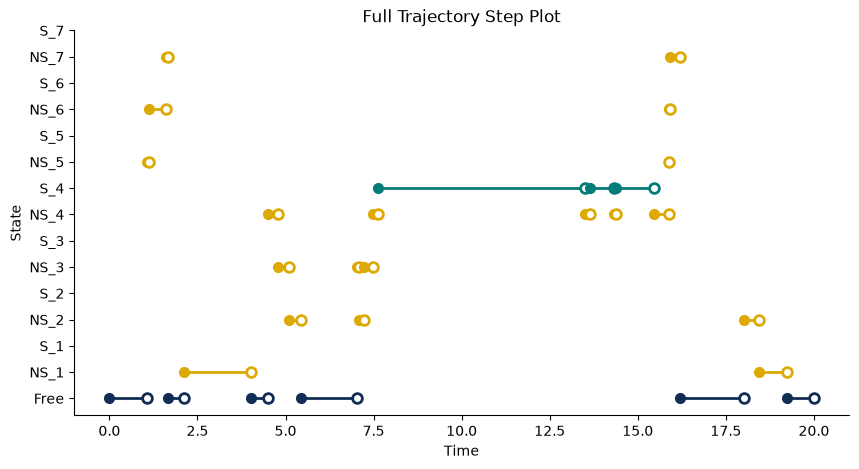

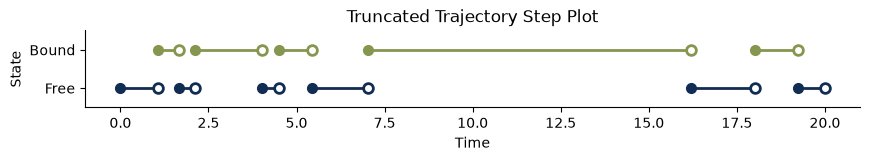

In [5]:
# Seed chosen so that the 20-time-unit window shows both short, aborted binding
# events and a long event with sequence recognition, as in Figure 2b.
set_numba_seed(80)
run_time = 20
sample_trajectory = SampleTrajectory(Q, i2s, trunc_dict, run_time)

sample_trajectory.plot_steps(step_palette, title = 'Full Trajectory Step Plot', dashed_lines=False, circles=True,figsize=(10,5))
sample_trajectory.plot_truncated_steps(truncated_palette, title = 'Truncated Trajectory Step Plot', dashed_lines=False, circles=True, figsize=(10,1))

## Figure 2c:

Integral of theoretical density, bound:  0.9867972549463753
Integral of theoretical density, free:  1.0025890060540497
Integral of theoretical density, S_4:  0.9821752850988502
Integral of theoretical density, NS_4:  1.0353797885217921
Coarse-grained plots for figure:


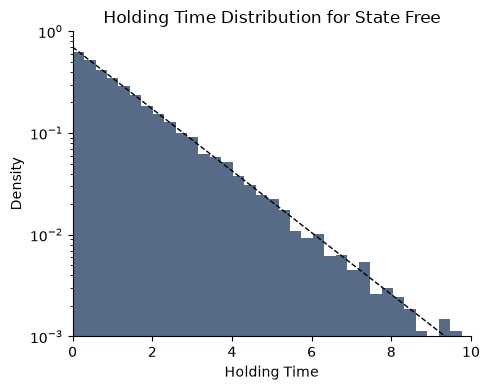

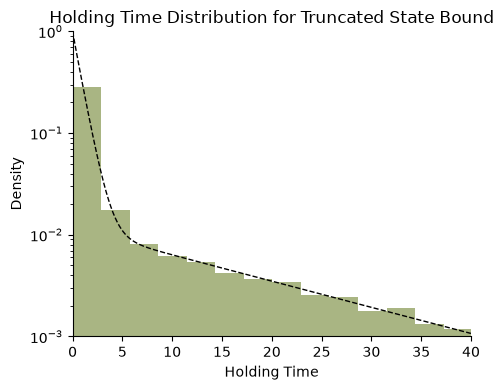

Sub-molecular plots for figure:


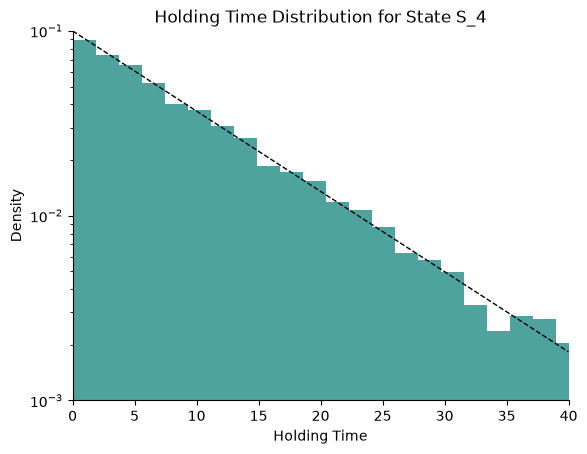

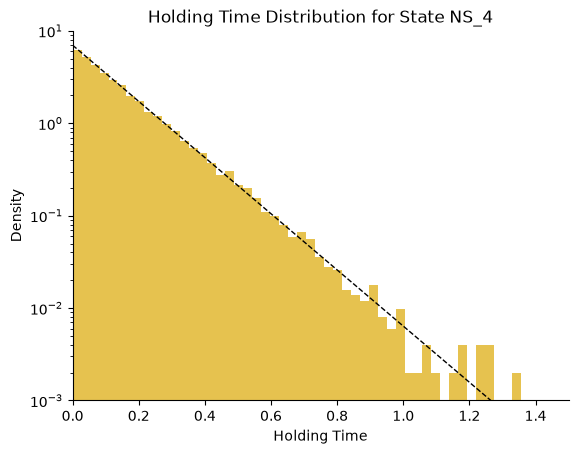

In [6]:
from scipy import linalg
#Transition rate matrix for off chain:
eqChain=ssc.SingleStrandChain(L, q01,q10,q11,q12,q21,1)
offChain=ssc.SingleStrandChain(L,0.0,q10,q11,q12,q21,1)
Qeq=eqChain.Q
Qoff=offChain.Q
#Indicator of bound state
deltaBound=np.array([0 if i==0 else 1 for i in range(2*L+1)])
deltaBound
#The initial state has to be a non-specific.
pIn = [0]
for i  in range(L):
    pIn.append(1)
    pIn.append(0)    
pIn = np.array(pIn) / np.sum(pIn)


#Defines plotrane:
(xrF, yrF) = ((0,10),(1e-3,1))
(xrB, yrB) = ((0,40),(1e-3,1))
(xrS4, yrS4) = ((0,40),(1e-3,1e-1))
(xrNS4, yrNS4) = ((0,1.5),(1e-3,1e1))



#Computes the holding time distribution of the coarse-grained bound state given starting at equilibrium
theoreticalDensityBound=[(t,-np.dot(pIn, np.dot(np.matmul(linalg.expm(Qoff*t),Qoff), deltaBound))) for t in np.arange(xrB[0],xrB[1],0.01)]
print("Integral of theoretical density, bound: ",np.sum(np.array(theoreticalDensityBound)[:,1]*0.01))

iState=eqChain.s2i["Free"]
theoreticalDensityFree=[(t,-Qeq[iState,iState]*np.exp(Qeq[iState,iState]*t)) for t in np.arange(xrF[0],xrF[1],0.01)]
print("Integral of theoretical density, free: ",np.sum(np.array(theoreticalDensityFree)[:,1]*0.01))

iState=eqChain.s2i["S_4"]
theoreticalDensityS4=[(t,-Qeq[iState,iState]*np.exp(Qeq[iState,iState]*t)) for t in np.arange(xrS4[0],xrS4[1],0.01)]
print("Integral of theoretical density, S_4: ",np.sum(np.array(theoreticalDensityS4)[:,1]*0.01))

iState=eqChain.s2i["NS_4"]
theoreticalDensityNS4=[(t,-Qeq[iState,iState]*np.exp(Qeq[iState,iState]*t)) for t in np.arange(xrNS4[0],xrNS4[1],0.01)]
print("Integral of theoretical density, NS_4: ",np.sum(np.array(theoreticalDensityNS4)[:,1]*0.01))

run_time=100000
set_numba_seed(42)

sample_trajectory = SampleTrajectory(Q, i2s, trunc_dict, run_time)

print("Coarse-grained plots for figure:")
sample_trajectory.plot_holding_time_distribution_truncated(palette=truncated_palette, state=0, bins=50, plotLog=True, showFit=False, theoretical_density=theoreticalDensityFree,  xRange=xrF, yRange=yrF)
sample_trajectory.plot_holding_time_distribution_truncated(palette=truncated_palette, state=1, bins=50, plotLog=True, showFit=False, theoretical_density=theoreticalDensityBound, xRange=xrB, yRange=yrB)
print("Sub-molecular plots for figure:")
sample_trajectory.plot_holding_time_distribution(palette=step_palette, state=8, bins=50, plotLog=True, theoretical_density=theoreticalDensityS4,  xRange=xrS4,  yRange=yrS4)
sample_trajectory.plot_holding_time_distribution(palette=step_palette, state=7, bins=50, plotLog=True, theoretical_density=theoreticalDensityNS4, xRange=xrNS4, yRange=yrNS4)

## Figure 2d:

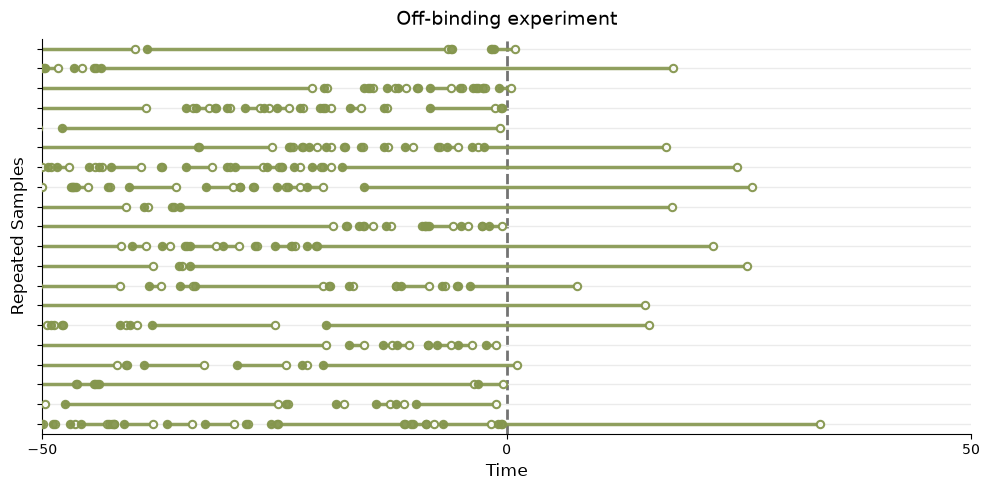

In [7]:
set_numba_seed(42)

run_time = 1000000
sample_trajectory = SampleTrajectory(Q, i2s, trunc_dict, run_time)

sample_trajectory.plot_steps_no_on_after_zero(trunc_palette=truncated_palette, title='Off-binding experiment', per_sample_start=-100, num_samples_plotted=20, skip_F_at_0=False, start_free=False, figsize=(10,5), circle_mode="both", xlim=(-50,50), xticks=[-50, 0, 50])

## Figure 2f:

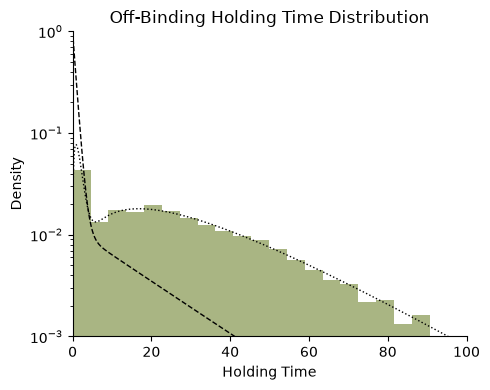

In [8]:
(xrB, yrB) = ((0,100),(1e-3,1))
theoreticalDensityBound=[(t,-np.dot(pIn, np.dot(np.matmul(linalg.expm(Qoff*t),Qoff), deltaBound))) for t in np.arange(xrB[0],xrB[1],0.01)]

exp_B = sample_trajectory.exp_B
theoreticalDensity=[(t,(-np.dot(pIn, np.dot(np.matmul(linalg.expm(Qoff*t),Qoff), deltaBound))) * t / exp_B) for t in np.arange(xrB[0],xrB[1],0.1)]

sample_trajectory.plot_holding_time_distribution_no_on_after_zero(palette=truncated_palette, bins=50, plotLog=True, per_sample_start=-100, skip_F_at_0=True, xRange=xrB, yRange=yrB, theoretical_density=theoreticalDensity, theoretical_density_2=theoreticalDensityBound)